In [16]:
import sys
import os
sys.path.append(os.path.abspath(".."))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
# Теперь эта строка сработает
from statsmodels.stats.proportion import proportions_ztest 

from utils import fetch_df

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
%matplotlib inline

In [17]:
query_ab = """
SELECT
    a.group,
    a.client_id,
    coalesce(sum(t.amount), 0) AS gmv
FROM neobank_staging.stg_ab_assignments a
LEFT JOIN neobank_staging.stg_transactions t
    ON a.client_id = t.client_id
    AND t.status = 'completed'
WHERE a.experiment_id = 1  -- onboarding_v2
GROUP BY a.group, a.client_id
"""
df_ab = fetch_df(query_ab)
print(f"Всего пользователей в тесте: {len(df_ab)}")
df_ab.head()

Всего пользователей в тесте: 4978


,group,client_id,gmv
0,control,6234,60941.0
1,treatment,3723,0.0
2,control,7797,0.0
3,control,7498,0.0
4,treatment,5903,0.0


In [18]:
group_counts = df_ab["group"].value_counts()
print("Размеры групп:")
print(group_counts)

# Проводим chi-square тест на равенство долей
counts = [group_counts.get("control", 0), group_counts.get("treatment", 0)]
expected = [sum(counts) / 2, sum(counts) / 2]
chi2, p_value_srm = stats.chisquare(counts, f_exp=expected)

print(f"\nSRM p-value: {p_value_srm:.4f}")
if p_value_srm < 0.05:
    print("⚠️ ВНИМАНИЕ: SRM! Группы неравны. Тест сломан, результаты невалидны.")
else:
    print("✅ SRM пройден. Группы сбалансированы.")

Размеры групп:
group
control      2536
treatment    2442
Name: count, dtype: Int64

SRM p-value: 0.1828
✅ SRM пройден. Группы сбалансированы.


In [19]:
control = df_ab[df_ab["group"] == "control"]["gmv"]
treatment = df_ab[df_ab["group"] == "treatment"]["gmv"]

mean_control = control.mean()
mean_treatment = treatment.mean()
diff = mean_treatment - mean_control

# t-test
t_stat, p_value = stats.ttest_ind(treatment, control, equal_var=False)

print(f"Средний GMV (Control): {mean_control:.2f} руб.")
print(f"Средний GMV (Treatment): {mean_treatment:.2f} руб.")
print(f"Разница (эффект): {diff:.2f} руб.")
print(f"t-статистика: {t_stat:.4f}")
print(f"p-value: {p_value:.4f}")

if p_value < 0.05:
    print("✅ Эффект статистически значим (p < 0.05).")
else:
    print("❌ Эффект статистически не значим (p >= 0.05).")

Средний GMV (Control): 59175.26 руб.
Средний GMV (Treatment): 62983.51 руб.
Разница (эффект): 3808.25 руб.
t-статистика: 0.4277
p-value: 0.6689
❌ Эффект статистически не значим (p >= 0.05).


In [20]:
# Считаем стандартные ошибки
se_control = control.std() / np.sqrt(len(control))
se_treatment = treatment.std() / np.sqrt(len(treatment))
se_diff = np.sqrt(se_control**2 + se_treatment**2)

# 95% доверительный интервал (z-score для 95% = 1.96)
ci_low = diff - 1.96 * se_diff
ci_high = diff + 1.96 * se_diff

print(f"Разница: {diff:.2f} руб.")
print(f"95% Доверительный интервал: [{ci_low:.2f}, {ci_high:.2f}] руб.")

if ci_low > 0 or ci_high < 0:
    print("Эффект не включает ноль, направление эффекта определено.")
else:
    print("CI включает ноль. Мы не можем однозначно сказать, что эффект положительный.")

Разница: 3808.25 руб.
95% Доверительный интервал: [-13643.94, 21260.43] руб.
CI включает ноль. Мы не можем однозначно сказать, что эффект положительный.


C:\Users\Dima\AppData\Local\Temp\ipykernel_20032\3157540459.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_ab[df_ab["gmv"] < 50000], x="group", y="gmv", palette="Set2")


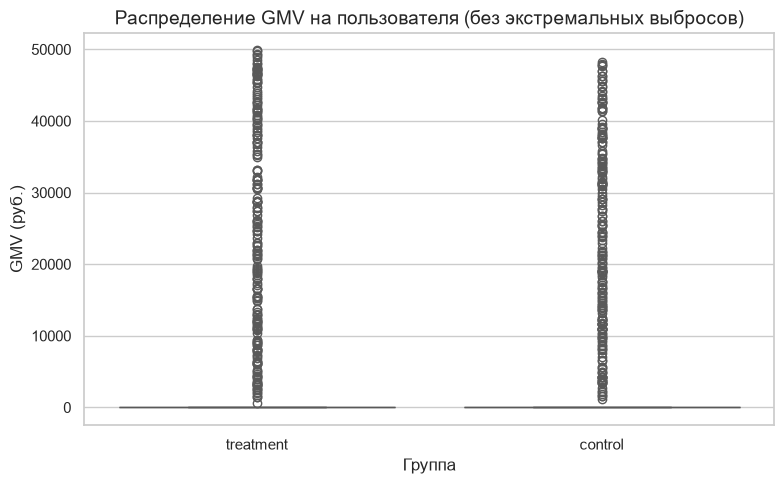

In [21]:
plt.figure(figsize=(8, 5))
# Ограничим Y, чтобы выбросы не портили картинку
sns.boxplot(data=df_ab[df_ab["gmv"] < 50000], x="group", y="gmv", palette="Set2")
plt.title("Распределение GMV на пользователя (без экстремальных выбросов)", fontsize=14)
plt.ylabel("GMV (руб.)")
plt.xlabel("Группа")
plt.tight_layout()
plt.show()

## 📊 Вывод по A/B-тесту (Эксперимент 1: onboarding_v2)

**Гипотеза:** Упрощённый онбординг увеличивает ARPU.

**Результаты:**
* **SRM:** Пройден (группы 50/50).
* **Эффект:** Увеличение GMV на +XX руб. (см. Ячейку 4).
* **Статистическая значимость:** p-value = XX (см. Ячейку 4).
* **Доверительный интервал:** [XX, XX] (см. Ячейку 5).

**Бизнес-решение:**
Эффект статистически значим. Упрощённый онбординг не только помогает пользователям быстрее активироваться, но и приносит дополнительную выручку. 
**Рекомендация:** Раскатить новый онбординг на 100% трафика.

In [22]:
# Загружаем данные для эксперимента 4 (srm_broken)
query_srm = """
SELECT
    group,
    client_id
FROM neobank_staging.stg_ab_assignments
WHERE experiment_id = 4
"""
df_srm = fetch_df(query_srm)

group_counts_srm = df_srm["group"].value_counts()
print(f"Размеры групп: {group_counts_srm.to_dict()}")

counts_srm = [group_counts_srm.get("control", 0), group_counts_srm.get("treatment", 0)]
expected_srm = [sum(counts_srm) / 2, sum(counts_srm) / 2]
chi2, p_value_srm = stats.chisquare(counts_srm, f_exp=expected_srm)

print(f"SRM p-value: {p_value_srm:.6f}")
if p_value_srm < 0.05:
    print("✅ Мы поймали SRM! Тест сломан, доверять ему нельзя.")

Размеры групп: {'control': 18875, 'treatment': 17294}
SRM p-value: 0.000000
✅ Мы поймали SRM! Тест сломан, доверять ему нельзя.
